# Simulating TOAs from a Weibull or a Poisson Distribution

The following function takes in a period [d], and active window [d], the number of points, and the distribution along with the distribution parameters to create a 1D array of the times of arrival from the first observation in units of days.

In the Poisson case, it takes anexpected rate of observations per, and draws a number of 



In [127]:
import numpy as np


def simulate_toas(
    period,
    window,
    n_points,
    dist="poisson",
    rate=None,          # Poisson: events per day of active time
    shape=None,         # Weibull shape k
    scale=None,         # Weibull scale lambda (days)
    window_start=0.0,   # offset (days) of the window start within the period. if = 0, the active window starts with the first observation
    t0=0.0,             # absolute time reference of the first period
    seed=None,
    max_windows=10_000_000,  # safety cap
):
    """
    Simulate times of arrival (days). The source is observable only during
    windows of length `window`, starting every `period` days.

    Poisson : per window, draw N ~ Poisson(rate * window in days), then place the N
              events uniformly in the window, following the dist of interarrival times for Poisson
    Weibull : per window, restart a renewal process at the window start, with
              Weibull-distributed waiting times; events beyond the window end
              are discarded.

    Returns a sorted 1-D array of length n_points.
    """
    # ---- validation ----
    if period <= 0 or window <= 0:
        raise ValueError("period and window must be > 0")
    if window > period:
        raise ValueError("window cannot exceed period")
    if n_points < 1:
        raise ValueError("n_points must be >= 1")

    rng = np.random.default_rng(seed)
    dist = dist.lower() #lowercasing

    if dist == "poisson":
        if rate is None or rate <= 0:
            raise ValueError("Poisson requires rate > 0")

        def events_in_one_window():
            n = rng.poisson(rate * window) #draw number of events in window
            return np.sort(rng.uniform(0.0, window, n))

    elif dist == "weibull":
        if shape is None or scale is None or shape <= 0 or scale <= 0:
            raise ValueError("Weibull requires shape > 0 and scale > 0")

        def events_in_one_window():
            out, t = [], 0.0
            while True:
                c = t + np.cumsum(scale * rng.weibull(shape, 64))
                inside = c < window
                out.append(c[inside])
                if not inside.all():   # a draw crossed the window end -> done
                    break
                t = c[-1]
            return np.concatenate(out)

    else:
        raise ValueError("dist must be 'poisson' or 'weibull'")

    # ---- fill windows one after another ----
    origin = t0 + window_start
    toas, n_have = [], 0
    for k in range(max_windows):
        ev = events_in_one_window()
        if ev.size:
            toas.append(origin + k * period + ev)
            n_have += ev.size
        if n_have >= n_points:
            break
    else:
        raise RuntimeError("max_windows reached before collecting n_points")

    return np.concatenate(toas)[:n_points]   # drop the excess (latest) events


if __name__ == "__main__":
    P, W, N = 16.3, 5.0, 3000000

    for label, kwargs in [
        ("Poisson", dict(dist="poisson", rate=))
        #("Weibull", dict(dist="weibull", shape=0.2, scale=0.01)),
    ]:
        toa = simulate_toas(P, W, N, **kwargs)
        phase = toa % P
        window_idx = np.floor(toa / P).astype(int)
        len(toa) == N and np.all(phase < W)
        print(f"{label}: n={len(toa)}")
        print("  TOAs:", np.round(toa, 3))
        print("  events per window:", np.bincount(window_idx)[np.unique(window_idx)])


Poisson: n=3000000
  TOAs: [1.0000000e-03 1.4000000e-02 1.8000000e-02 ... 6.7906451e+04 6.7906458e+04
 6.7906468e+04]
  events per window: [751 736 689 ... 747 675 106]


0.00567445234929187


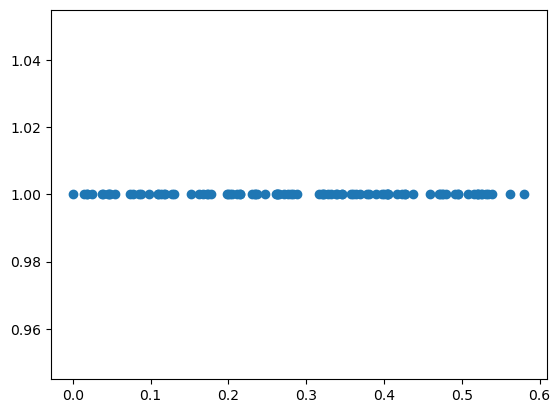

In [128]:
import matplotlib.pyplot as plt
plt.scatter (toa[0:100], np.ones(len(toa[0:100])))
print(toa[50]- toa[49])

(array([2.99768e+05, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00

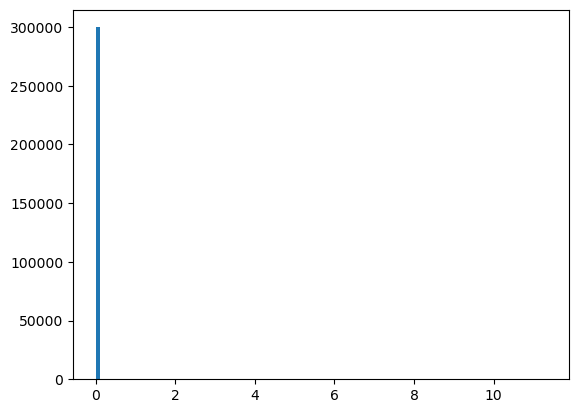

In [70]:
plt.hist(np.diff(toa), bins = 100)

# Create mask.

Want to mask all events not happening within a 10 minute interval, every 24 hours


34.00210628515197
21168


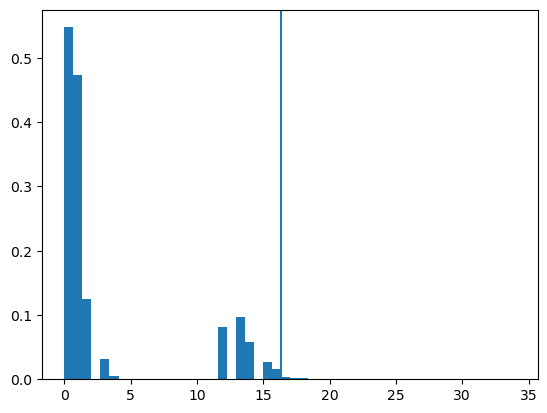

In [129]:
import numpy.ma as ma


def observing_window_mask(toas, window = 10 / 1440, period = 1.0, t_offset = 0.0):
    t_offset = toas[0]
    toas_rem = np.mod(toas - t_offset, period)
    return toas_rem < window


mask = observing_window_mask(toa)
toas_masked = toa[mask]
gaps = np.diff(toas_masked)
gaps = np.sort(gaps)
print(max(gaps))
#g_mask = [g < 100 for g in gaps]
#gaps = gaps[g_mask]
#plt.scatter(toas_masked, np.ones(len(toas_masked)))
plt.hist(gaps, bins = 50, density = True)
plt.axvline(16.3)
print(len(gaps))


In [153]:
if __name__ == "__main__":
    P, W, N = 16.3, 4.0, 1000000

    for label, kwargs in [
        #("Poisson", dict(dist="poisson", rate=260))
        ("Weibull", dict(dist="weibull", shape=0.07, scale= 30/1440)),
    ]:
        toa_w = simulate_toas(P, W, N, **kwargs)
        phase = toa % P
        window_idx_w = np.floor(toa_w / P).astype(int)
        len(toa_w) == N and np.all(phase < W)
        print(f"{label}: n={len(toa_w)}")
        print("  TOAs:", np.round(toa_w, 3))
        print("  events per window:", np.bincount(window_idx_w)[np.unique(window_idx_w)])

Weibull: n=1000000
  TOAs: [1.63000000e+01 1.86540000e+01 1.90030000e+01 ... 5.12331820e+06
 5.12331824e+06 5.12331824e+06]
  events per window: [5 1 4 ... 3 3 3]


6031.000434197951
[ True False False ... False False False]


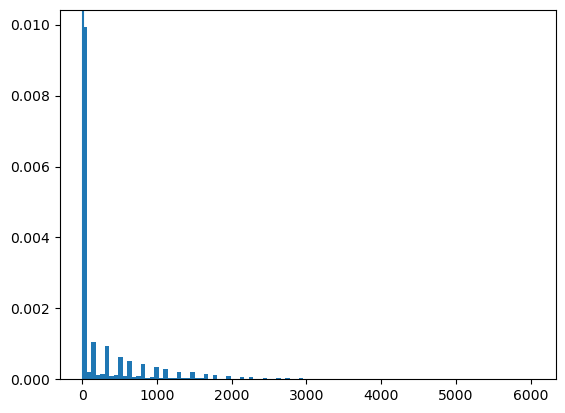

In [154]:
mask = observing_window_mask(toa_w, window = 10 / 1440)
toas_w_masked = toa_w[mask]
gaps = np.diff(toas_w_masked)
gaps = np.sort(gaps)
print(max(gaps))
#g_mask = [g < 100 for g in gaps]
#gaps = gaps[g_mask]
#plt.scatter(toas_masked, np.ones(len(toas_masked)))
plt.hist(gaps, bins = 100, density = True)
plt.axvline(16.3)
print(mask)

In [163]:
from generate_repeater import poisson_window, weibull_widndow, generate_repeater_from_dist

generated_toas = generate_repeater_from_dist(16.3, 5, 999999, "poisson", 1440 / 15)
plot_waiting_time_distribution(generated_toas)

ImportError: cannot import name 'generate_repeater_from_dist' from 'generate_repeater' (d:\Thesis\main\generate_repeater.py)